# TEST 2 avec word to vec + tfidf

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

print('Numpy:', np.__version__)
print('Pandas:', pd.__version__)

Numpy: 2.4.2
Pandas: 3.0.1


In [4]:
csv_path = "../Student_Dataset.csv"
dataframe = pd.read_csv(csv_path, encoding='utf-8-sig')
print(dataframe.head())
print(dataframe.shape)
print(dataframe.info())

                                                   1  \
2                                           0x000000   
3                                           0x000000   
4  A short sprint brought on a twinge in the midd...   
5                                           0x000000   
6  A sudden twist while reaching for a bag made o...   

  On uneven paths the heel feels wobbly side‑to‑side. Slanted pavements bring a quick aching shift under the ankle when I step.  
2  The feverish feeling eased, but I’m now breath...                                                                             
3  While working in the garden, I touched a metal...                                                                             
4                                                NaN                                                                             
5  I accidentally left my hand on a hot mug for a...                                                                             
6            

In [6]:
csv_path = "../Student_Dataset.csv"

tempdf = pd.read_csv(csv_path, encoding='utf-8-sig', header=None,
    names=['id', 'col2', 'col3'])

tempdf['text'] = np.where(tempdf['col2'] == '0x000000', tempdf['col3'], tempdf['col2'])
dataframe = tempdf[['id', 'text']]



print(dataframe.head())
print(dataframe.shape)
print(dataframe.info())
print('nombres elements louche dans le df: ', dataframe['text'].str.contains('0x000000').sum())


   id                                               text
0   1  On uneven paths the heel feels wobbly side‑to‑...
1   2  The feverish feeling eased, but I’m now breath...
2   3  While working in the garden, I touched a metal...
3   4  A short sprint brought on a twinge in the midd...
4   5  I accidentally left my hand on a hot mug for a...
(1011, 2)
<class 'pandas.DataFrame'>
RangeIndex: 1011 entries, 0 to 1010
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      1011 non-null   int64
 1   text    1011 non-null   str  
dtypes: int64(1), str(1)
memory usage: 15.9 KB
None
nombres elements louche dans le df:  0


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
import re

vectorizer = TfidfVectorizer(stop_words='english')
stop_words = vectorizer.get_stop_words()

def remove_stop_words(text):
    tokens = text.lower().split()
    tokens = [t for t in tokens if t not in stop_words]
    return ' '.join(tokens)

import re

def remove_numbers(text):
    return re.sub(r'\d+\.?\d*\S*', '', text)



dataframe['clean_text'] = dataframe['text'].apply(remove_stop_words)
dataframe['clean_text'] = dataframe['clean_text'].apply(remove_numbers)

print(dataframe[['text', 'clean_text']].head(3))


                                                text  \
0  On uneven paths the heel feels wobbly side‑to‑...   
1  The feverish feeling eased, but I’m now breath...   
2  While working in the garden, I touched a metal...   

                                          clean_text  
0  uneven paths heel feels wobbly side‑to‑side. s...  
1  feverish feeling eased, i’m breathing faster d...  
2  working garden, touched metal grill stove. lef...  


ICI on inclus le fait de plustipliquer chaque embedding de mot par TFIDF afin d'avoir des embeddings pondéré  et pouvoir ensnuite possiblement faire un PCA significative .

refelctions : La pCA ne se fait elle pas indirectement lorsque la ponderation exerce une moyen passive ou les éléments non discriminants sont deja réduits au silence sans pour autnant etre supprimé ? 

In [8]:
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. TF-IDF
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(dataframe['clean_text'])
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()

# 2. Word2Vec
tokenized = dataframe['clean_text'].apply(str.split).tolist()
w2v_model = Word2Vec(sentences=tokenized, vector_size=100, window=5, min_count=1, workers=4, epochs=50)

# 3. Vecteurs documents = moyenne pondérée W2V par TF-IDF
def get_pond_vector(doc_idx):
    row = tfidf_matrix[doc_idx]
    weighted_vec = np.zeros(w2v_model.vector_size)
    total_weight = 0
    for col_idx in row.nonzero()[1]:
        word = tfidf_feature_names[col_idx]
        tfidf_weight = row[0, col_idx]
        if word in w2v_model.wv:
            weighted_vec += tfidf_weight * w2v_model.wv[word]
            total_weight += tfidf_weight
    if total_weight > 0:
        weighted_vec /= total_weight
    return weighted_vec

tfidf_w2v_matrix = np.array([get_pond_vector(i) for i in range(tfidf_matrix.shape[0])])

print("TF-IDF shape:", tfidf_matrix.shape)
print("TF-IDF x W2V shape:", tfidf_w2v_matrix.shape)


TF-IDF shape: (1011, 2130)
TF-IDF x W2V shape: (1011, 100)


on constate la réduction de dimension dont je parle mais c'tes différents car la reduction de dimenssion ce fait en gardant la rela tions de smots et ne regardant pas la variance explqiué ...;

Testons pour chaque valeur de K cluster :

k=2 -> silhouette cosine: 0.4933
k=3 -> silhouette cosine: 0.3717
k=4 -> silhouette cosine: 0.4624
k=5 -> silhouette cosine: 0.5039
k=6 -> silhouette cosine: 0.4820
k=7 -> silhouette cosine: 0.4666
k=8 -> silhouette cosine: 0.4532
k=9 -> silhouette cosine: 0.3275
k=10 -> silhouette cosine: 0.3224
k=11 -> silhouette cosine: 0.3047
k=12 -> silhouette cosine: 0.3157
k=13 -> silhouette cosine: 0.2917
k=14 -> silhouette cosine: 0.2915


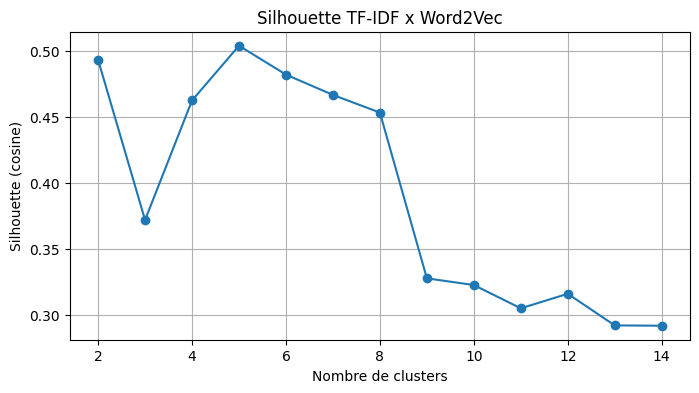

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test sur plusieurs valeurs de k
silhouettes = []
K_range = range(2, 15)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(tfidf_w2v_matrix)
    score = silhouette_score(tfidf_w2v_matrix, km.labels_, metric='cosine')
    silhouettes.append(score)
    print(f"k={k} -> silhouette cosine: {score:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(list(K_range), silhouettes, marker='o')
plt.xlabel('Nombre de clusters')
plt.ylabel('Silhouette (cosine)')
plt.title('Silhouette TF-IDF x Word2Vec')
plt.grid(True)
plt.show()


grace au test de valeurs cas en affichant le score de silhouette cosine on constate que 5 est techniquement le meilleurs k cluster pour ce dataset :

Taille clusters: [282 122 218  94 295]


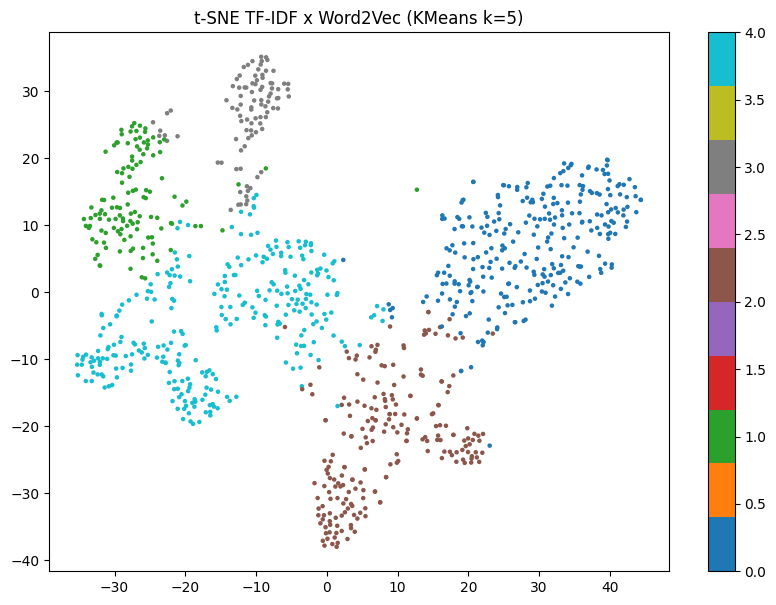

In [10]:
from sklearn.manifold import TSNE

# KMeans final avec k=5
kmeans_w2v = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans_w2v.fit(tfidf_w2v_matrix)

print("Taille clusters:", np.bincount(kmeans_w2v.labels_))

# t-SNE pour visualiser
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
w2v_tsne = tsne.fit_transform(tfidf_w2v_matrix)

plt.figure(figsize=(10, 7))
plt.scatter(w2v_tsne[:, 0], w2v_tsne[:, 1], c=kmeans_w2v.labels_, cmap='tab10', s=5)
plt.title('t-SNE TF-IDF x Word2Vec (KMeans k=5)')
plt.colorbar()
plt.show()


## Verification manuel :

In [11]:
for i in range(5):
    print(f"\n=== Cluster {i} ({(kmeans_w2v.labels_ == i).sum()} phrases) ===")
    mask = kmeans_w2v.labels_ == i
    for text in dataframe[mask]['text'].head(5):
        print(f"  - {text[:100]}...")



=== Cluster 0 (282 phrases) ===
  - On uneven paths the heel feels wobbly side‑to‑side. Slanted pavements bring a quick aching shift und...
  - A short sprint brought on a twinge in the middle of the back of my thigh. It’s tender along a band a...
  - A sudden twist while reaching for a bag made one side of my lower back feel ‘switched off’ and sore....
  - I slipped on ice and landed seated. Since then sitting on hard chairs is very uncomfortable, and lea...
  - There’s a small sore area on the top of my foot that flares when I push off while walking. Tight sho...

=== Cluster 1 (122 phrases) ===
  - I feel an unexplained pressure behind my eyes and a dull ache in my neck. It’s mild but persistent....
  - Since last week, my right ear has been aching and I noticed a slight fluid drainage. I feel a buzzin...
  - My right ear hurts like a stone in the middle. The pain is stronger when I drive. I had a flu 5 days...
  - My right ear hurts when I swallow, and I feel pressure when I sit i

On constate des cluster plsutot bien définit malgres le fait que le cluster 5 est un peu melanger et que parfoisd la différence entre rhum et maladie respiratoire ect est assez fine  mais dnas l'ensemble de bon résultats .